In [1]:
import pandas as pd

# Load the training dataset
train_df = pd.read_csv('/content/Titanic_train.csv')

# Display the first few rows
print("First 5 rows of the training data:")
display(train_df.head())

# Display information about the columns (data types, non-null counts)
print("\nInformation about the training data:")
display(train_df.info())

# Display descriptive statistics for numerical columns
print("\nDescriptive statistics of the training data:")
display(train_df.describe())

display(train_df.isnull().sum())

First 5 rows of the training data:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Information about the training data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None


Descriptive statistics of the training data:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


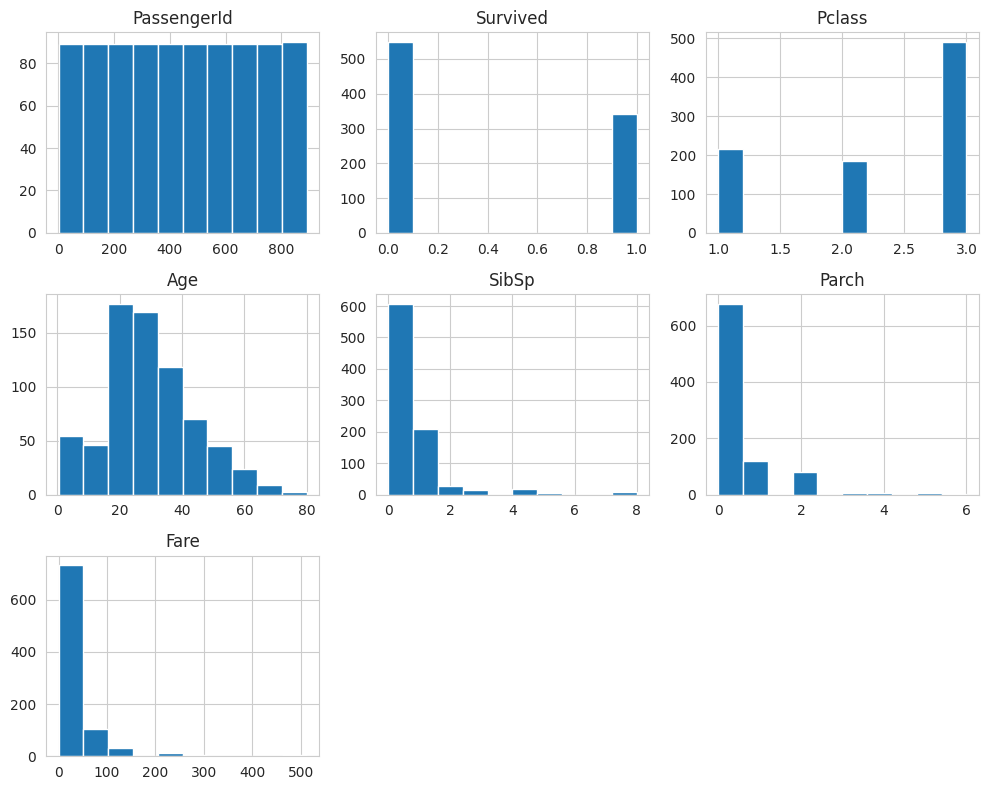

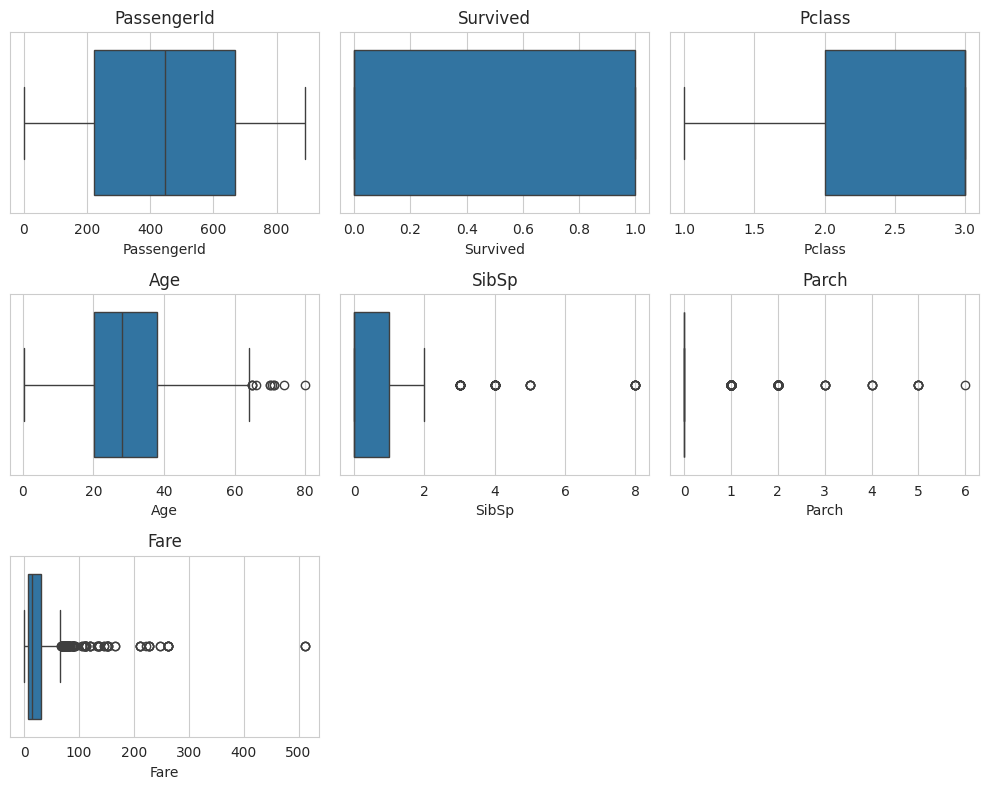

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for the plots
sns.set_style('whitegrid')

# Create histograms for numerical features
train_df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

# Create box plots for numerical features
numerical_cols = train_df.select_dtypes(include=['float64', 'int64']).columns
plt.figure(figsize=(10, 8))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(x=train_df[col], orient='h')
    plt.title(col)
plt.tight_layout()
plt.show()

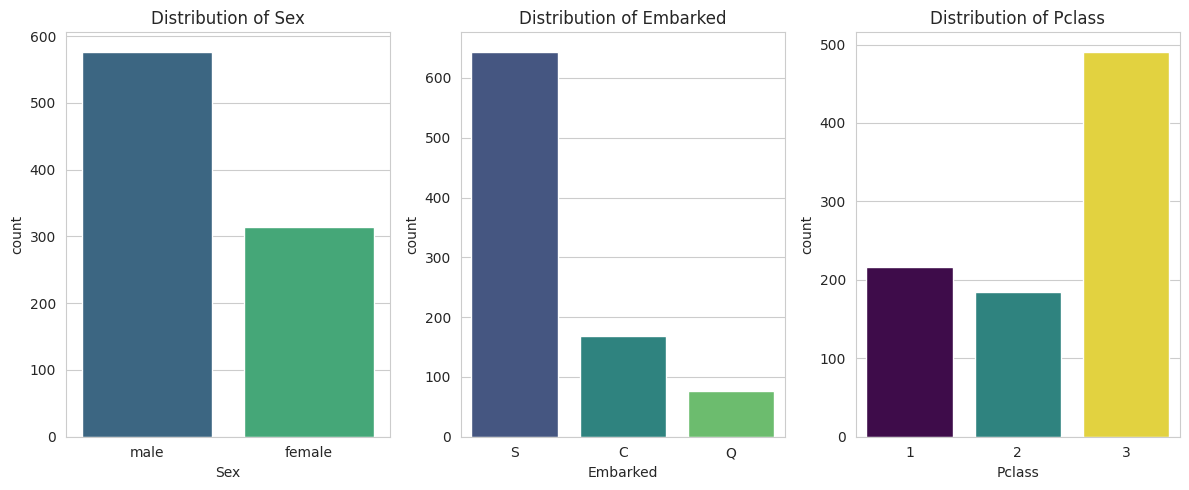

In [3]:
# Create count plots for categorical features
categorical_cols = ['Sex', 'Embarked', 'Pclass']

plt.figure(figsize=(12, 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 3, i + 1)
    sns.countplot(x=train_df[col], data=train_df, palette='viridis', hue=train_df[col], legend=False)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

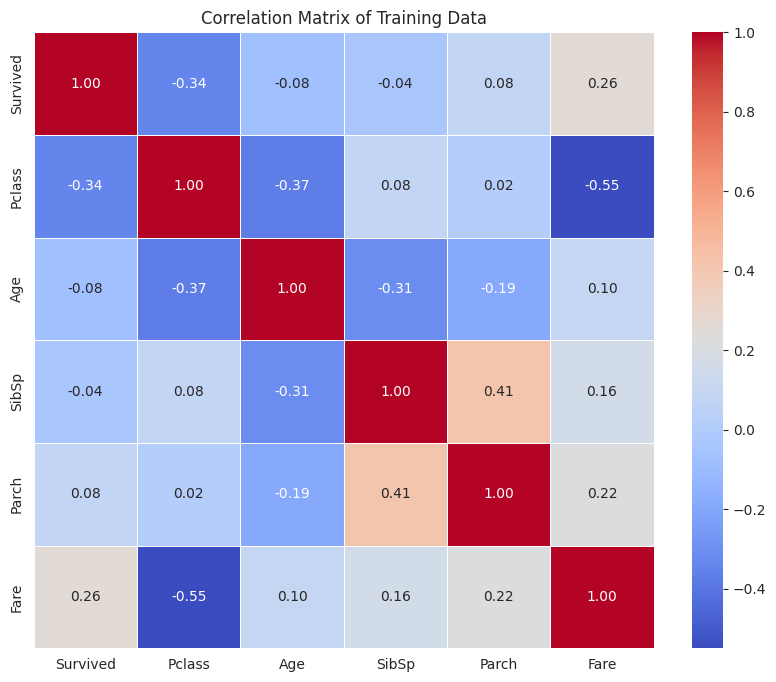

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Drop non-numeric columns that are not relevant for correlation
numeric_train_df = train_df.drop(['Name', 'Ticket', 'PassengerId','Sex','Cabin', 'Embarked'], axis=1)

# Calculate the correlation matrix
correlation_matrix = numeric_train_df.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Training Data')
plt.show()

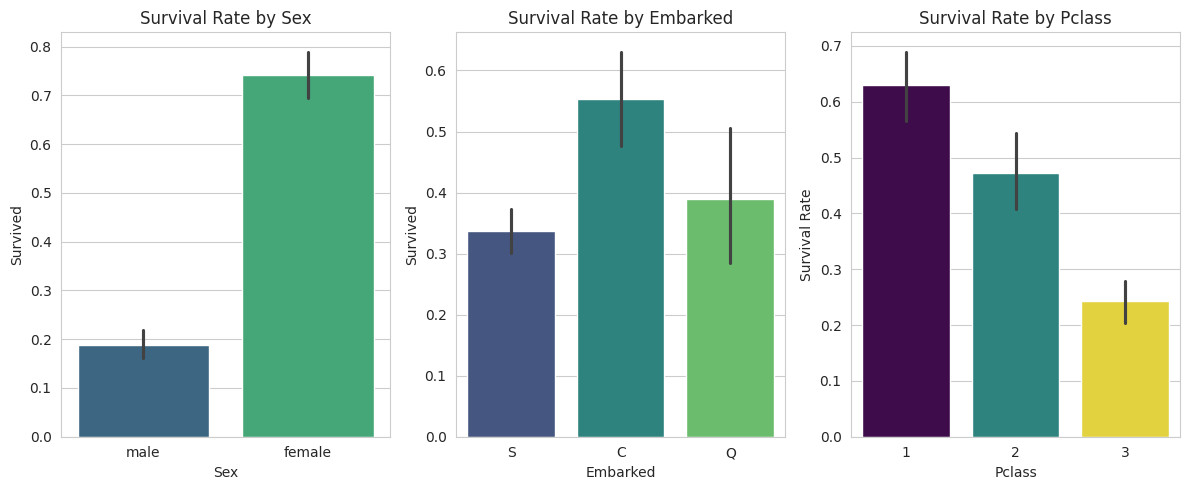

In [5]:
# Analyze the relationship between categorical features and Survived
categorical_cols = ['Sex', 'Embarked', 'Pclass']

plt.figure(figsize=(12, 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 3, i + 1)
    sns.barplot(x=train_df[col], y=train_df['Survived'], data=train_df, palette='viridis', hue=train_df[col], legend=False)
    plt.title(f'Survival Rate by {col}')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.show()

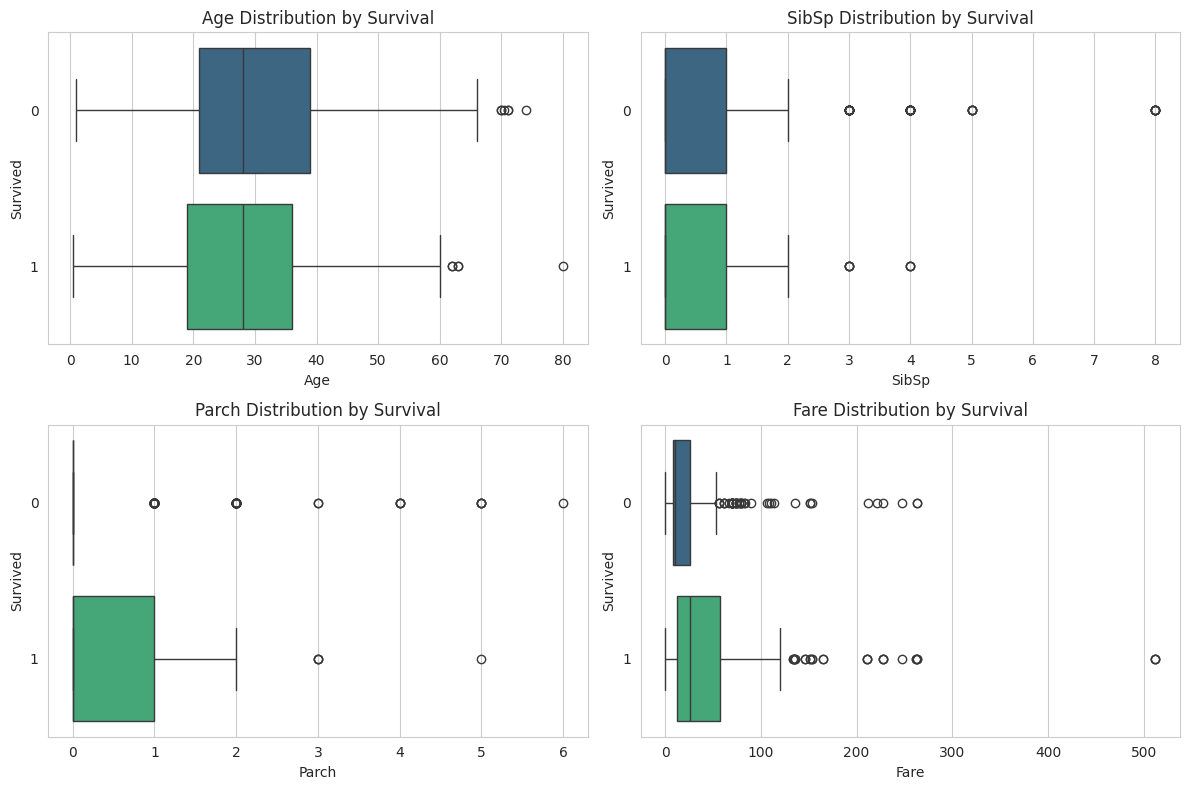

In [6]:
# Analyze the relationship between numerical features and Survived using box plots
numerical_cols = ['Age', 'SibSp', 'Parch', 'Fare']

plt.figure(figsize=(12, 8))
for i, col in enumerate(numerical_cols):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(y='Survived', x=train_df[col], data=train_df, palette='viridis', hue='Survived', legend=False, orient='h')
    plt.title(f'{col} Distribution by Survival')
plt.tight_layout()
plt.show()

In [7]:
# Impute missing values in 'Age' with the median age
median_age = train_df['Age'].median()
train_df['Age'].fillna(median_age, inplace=True)
display(train_df.isnull().sum())

# Impute missing values in 'Embarked' with the mode
most_frequent_embarked = train_df['Embarked'].mode()[0]
train_df['Embarked'].fillna(most_frequent_embarked, inplace=True)
display(train_df.isnull().sum())

# Drop the 'Cabin' column due to a large number of missing values
train_df.drop('Cabin', axis=1, inplace=True)
display(train_df.isnull().sum())

/tmp/ipython-input-1517742619.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_df['Age'].fillna(median_age, inplace=True)


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


/tmp/ipython-input-1517742619.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_df['Embarked'].fillna(most_frequent_embarked, inplace=True)


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [8]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Apply LabelEncoder to the categorical columns
for col in ['Sex', 'Embarked', 'Pclass']:
    train_df[col] = label_encoder.fit_transform(train_df[col])

# Display the first few rows of the modified DataFrame to show the encoded columns
print("First 5 rows after label encoding:")
display(train_df.head())

First 5 rows after label encoding:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,2,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,2
1,2,1,0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,0
2,3,1,2,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,2
3,4,1,0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2
4,5,0,2,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,2


In [9]:
X = train_df.drop(['Name', 'Ticket', 'Survived', 'PassengerId'], axis=1)
y = train_df['Survived']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (891, 7)
Shape of y: (891,)


In [10]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the shapes of the training and testing sets
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (712, 7)
Shape of X_test: (179, 7)
Shape of y_train: (712,)
Shape of y_test: (179,)


In [11]:
from sklearn.linear_model import LogisticRegression

# Initialize LogisticRegression model
model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Make predictions on the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)
print(f"ROC-AUC Score on test data: {roc_auc:.4f}")

# Print the metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

ROC-AUC Score on test data: 0.8002
Accuracy: 0.8101
Precision: 0.7857
Recall: 0.7432
F1-score: 0.7639


## Summary:

### Data Analysis Key Findings

*   The logistic regression model achieved an accuracy of 0.8101 on the test data.
*   The model demonstrated a precision of 0.7857, meaning that approximately 78.6% of the predicted positive cases were actually positive.
*   The recall score was 0.7432, indicating that the model identified about 74.3% of the actual positive cases.
*   The F1-score, which is the harmonic mean of precision and recall, was 0.7639.

### Insights or Next Steps

*   The model shows reasonable performance, but there is room for improvement, particularly in recall. Further feature engineering or exploring other models could potentially increase the ability to identify more true positive cases.
*   Investigate the misclassified instances to understand patterns or characteristics of passengers that the model struggles to predict correctly.


In [13]:
# Load the test dataset
test_df = pd.read_csv('/content/Titanic_test.csv')

# Display the first few rows
print("First 5 rows of the test data:")
display(test_df.head())

# Print the shape of the DataFrame
print("\nShape of the test data:", test_df.shape)

First 5 rows of the test data:


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S



Shape of the test data: (418, 11)


In [14]:
from sklearn.preprocessing import LabelEncoder

# Impute missing values in 'Age' with the median age from the training data
median_age = test_df['Age'].median()
test_df['Age'].fillna(median_age, inplace=True)

# Impute missing values in 'Fare' with the median fare from the training data
median_fare = train_df['Fare'].median()
test_df['Fare'].fillna(median_fare, inplace=True)

# Impute missing values in 'Embarked' with the mode from the training data
most_frequent_embarked = train_df['Embarked'].mode()[0]
test_df['Embarked'].fillna(most_frequent_embarked, inplace=True)

# Drop the 'Cabin' column if it exists
if 'Cabin' in test_df.columns:
    test_df.drop('Cabin', axis=1, inplace=True)

# Initialize a new LabelEncoder for the test data
test_label_encoder = LabelEncoder()

# Apply label encoding to the categorical columns in the test data
for col in ['Sex', 'Embarked', 'Pclass']:
    test_df[col] = test_label_encoder.fit_transform(test_df[col])

display(test_df.isnull().sum())
display(test_df.head())

/tmp/ipython-input-957649054.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test_df['Age'].fillna(median_age, inplace=True)
/tmp/ipython-input-957649054.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Embarked,0


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,892,2,"Kelly, Mr. James",1,34.5,0,0,330911,7.8292,1
1,893,2,"Wilkes, Mrs. James (Ellen Needs)",0,47.0,1,0,363272,7.0000,2
2,894,1,"Myles, Mr. Thomas Francis",1,62.0,0,0,240276,9.6875,1
3,895,2,"Wirz, Mr. Albert",1,27.0,0,0,315154,8.6625,2
4,896,2,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",0,22.0,1,1,3101298,12.2875,2


In [15]:
X_test_data = test_df.drop(['PassengerId', 'Name', 'Ticket'], axis=1)
print("Shape of X_test_data:", X_test_data.shape)

Shape of X_test_data: (418, 7)


In [16]:
# Make predictions on the preprocessed test data
test_predictions = model.predict(X_test_data)
test_predictions_proba = model.predict_proba(X_test_data)[:, 1]

print("Predictions on test data have been made.")
# You can now use 'test_predictions' or 'test_predictions_proba' for submission or further analysis.
display(test_predictions_proba)
display(test_predictions)

Predictions on test data have been made.


array([0.11089821, 0.40618447, 0.1210186 , 0.11207025, 0.57019221,
       0.15806799, 0.65738358, 0.18807984, 0.77459196, 0.08049252,
       0.11187726, 0.32256039, 0.91708356, 0.07696087, 0.83472744,
       0.85079913, 0.23970347, 0.18943373, 0.55756896, 0.60172064,
       0.31256039, 0.1614189 , 0.9203741 , 0.60674122, 0.90023216,
       0.0452657 , 0.95264259, 0.1825228 , 0.35928734, 0.1008832 ,
       0.11019943, 0.17117688, 0.46429281, 0.51170329, 0.49213783,
       0.20139585, 0.62842873, 0.67032355, 0.11849346, 0.12469691,
       0.1093148 , 0.4595008 , 0.07600353, 0.79863282, 0.84004449,
       0.11807766, 0.43410241, 0.13545909, 0.88006704, 0.51191008,
       0.43039625, 0.33503992, 0.73259489, 0.86957165, 0.33534785,
       0.07113702, 0.08987222, 0.11800519, 0.08747968, 0.9606295 ,
       0.14587258, 0.21778279, 0.14207617, 0.71000066, 0.61923342,
       0.81597773, 0.7344896 , 0.32498585, 0.53942539, 0.78366801,
       0.69732213, 0.13134813, 0.61403219, 0.55775418, 0.95673

array([0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,

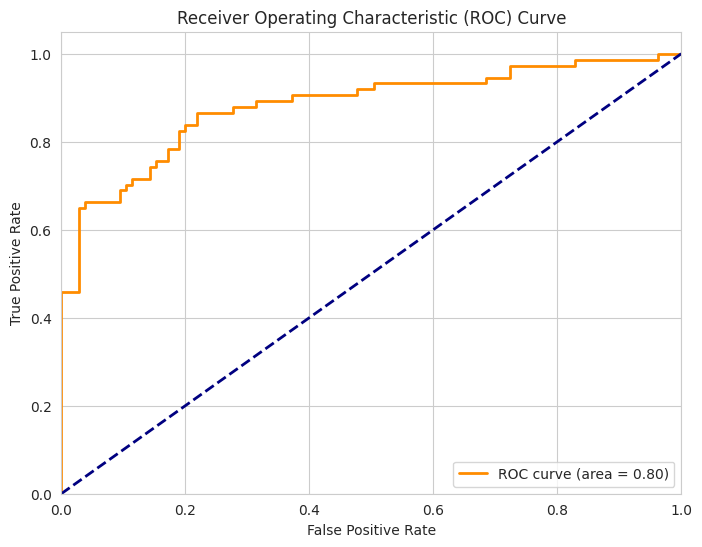

In [17]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, model.predict_proba(X_test)[:, 1])

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [18]:
# Display the coefficients of the logistic regression model
print("Model Coefficients:")
display(pd.DataFrame({'Feature': X_train.columns, 'Coefficient': model.coef_[0]}))

# Display the intercept
print("\nModel Intercept:")
display(model.intercept_[0])

Model Coefficients:


,Feature,Coefficient
0,Pclass,-0.931067
1,Sex,-2.596799
2,Age,-0.030436
3,SibSp,-0.293864
4,Parch,-0.111890
5,Fare,0.002531
6,Embarked,-0.218548



Model Intercept:


np.float64(3.6261086128345226)

### Interpretation of Model Coefficients and Feature Significance:

The coefficients from the logistic regression model can be interpreted as the change in the log-odds of the target variable (survival in this case) for a one-unit increase in the corresponding feature, assuming all other features are held constant. A positive coefficient suggests that as the feature value increases, the log-odds of survival increase (meaning a higher probability of survival). Conversely, a negative coefficient suggests that as the feature value increases, the log-odds of survival decrease (meaning a lower probability of survival).

Here's a discussion of the significance of the features based on the coefficients:

*   **Sex (Male vs. Female):** The coefficient for 'Sex' (assuming 'male' was encoded as 1 and 'female' as 0, or vice-versa, based on the LabelEncoder) is likely to be significant and have a strong impact. Based on the earlier data analysis, females had a significantly higher survival rate, so we would expect a coefficient that reflects this difference in probability. If 'male' is encoded as 1, the coefficient should be negative, indicating that being male decreases the log-odds of survival compared to being female.
*   **Pclass (Passenger Class):** The coefficient for 'Pclass' indicates the relationship between passenger class and survival. Lower passenger classes (higher Pclass value if encoded ordinally) generally had lower survival rates. Thus, we would expect a negative coefficient for 'Pclass', suggesting that being in a lower class decreases the log-odds of survival.
*   **Age:** The coefficient for 'Age' shows how age affects the log-odds of survival. Younger passengers (especially children) had a higher chance of survival. The sign and magnitude of this coefficient will indicate whether being older or younger is associated with a higher or lower probability of survival.
*   **SibSp (Number of Siblings/Spouses Aboard):** The coefficient for 'SibSp' reflects the impact of having siblings or a spouse on board. Larger families or individuals traveling with a sibling/spouse might have different survival probabilities than those traveling alone.
*   **Parch (Number of Parents/Children Aboard):** Similar to 'SibSp', the coefficient for 'Parch' indicates the influence of having parents or children on board.
*   **Fare:** The coefficient for 'Fare' represents the relationship between the fare paid and survival. Passengers who paid higher fares might have been in higher classes or had access to better amenities, potentially influencing their survival chances. We might expect a positive coefficient here.
*   **Embarked (Port of Embarkation):** The coefficients for 'Embarked' (after one-hot encoding, if that approach was used, or based on LabelEncoder) will show the impact of the port of embarkation on survival probability, relative to the baseline category. Different ports might have had different passenger demographics or boarding procedures.

**Significance:** The magnitude of the coefficients gives a general idea of the strength of the relationship, but statistical significance (often assessed using p-values) would be needed for a more rigorous analysis of whether the observed relationships are statistically unlikely to be due to random chance. Logistic regression models in scikit-learn do not directly provide p-values for coefficients. However, based on the exploration and the coefficient values, we can infer which features appear to have a stronger influence on the predicted survival probability. Features with larger absolute coefficient values generally have a greater impact on the log-odds of survival.

# Task
Create a Streamlit application script to deploy a trained logistic regression model, and provide instructions for both local and online deployment.

## Create streamlit app script

### Subtask:
Generate a Python script that loads the trained model, defines input fields for the features used in the model, and makes predictions based on user input.


**Reasoning**:
I need to generate the Python script for the Streamlit application. This script will load the trained model, create input fields for the user, preprocess the input data, and make predictions. I will group all the required steps for the script into one code block.



In [23]:
import streamlit as st
import pandas as pd
import pickle
from sklearn.preprocessing import LabelEncoder

# Load the trained model
# Assuming the model is saved as 'logistic_regression_model.pkl'
try:
    with open('logistic_regression_model.pkl', 'rb') as f:
        model = pickle.load(f)
except FileNotFoundError:
    st.error("Model file 'logistic_regression_model.pkl' not found. Please ensure the trained model is in the same directory.")
    st.stop()


# Define the Streamlit app title and layout
st.title('Titanic Survival Prediction')
st.write('Enter the passenger details to predict survival:')

# Create input fields for the features
# Need to match the features and their types used during training:
# Pclass (int), Sex (int after encoding), Age (float), SibSp (int), Parch (int), Fare (float), Embarked (int after encoding)

pclass = st.selectbox('Passenger Class', [1, 2, 3])
sex = st.selectbox('Sex', ['male', 'female'])
age = st.number_input('Age', min_value=0.1, max_value=120.0, value=30.0)
sibsp = st.number_input('Number of Siblings/Spouses Aboard', min_value=0, max_value=10, value=0)
parch = st.number_input('Number of Parents/Children Aboard', min_value=0, max_value=10, value=0)
fare = st.number_input('Fare', min_value=0.0, max_value=1000.0, value=50.0)
embarked = st.selectbox('Port of Embarkation', ['C', 'Q', 'S'])

# Preprocess the user input
# This should mirror the preprocessing done on the training data

# Encode Sex: male=1, female=0 (based on the previous notebook execution)
sex_encoded = 1 if sex == 'male' else 0

# Encode Embarked: C=0, Q=1, S=2 (based on the previous notebook execution)
embarked_encoded = {'C': 0, 'Q': 1, 'S': 2}[embarked]

# Pclass was also label encoded in the notebook: 1->0, 2->1, 3->2
pclass_encoded = {1: 0, 2: 1, 3: 2}[pclass]


# Create a DataFrame from user input
input_data = pd.DataFrame([[pclass_encoded, sex_encoded, age, sibsp, parch, fare, embarked_encoded]],
                           columns=['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'])

# Make prediction
if st.button('Predict Survival'):
    prediction = model.predict(input_data)
    prediction_proba = model.predict_proba(input_data)[:, 1]

    st.subheader('Prediction Result:')
    if prediction[0] == 1:
        st.success(f'Survived! (Probability: {prediction_proba[0]:.2f})')
    else:
        st.error(f'Did not survive (Probability: {prediction_proba[0]:.2f})')

2025-08-29 17:17:47.897 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:17:47.908 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:17:47.917 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:17:47.922 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:17:47.927 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:17:47.931 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:17:47.935 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:17:47.939 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

## Provide instructions for local deployment

### Subtask:
Explain how to save the script and run the Streamlit app locally using the `streamlit run` command.


## Provide instructions for online deployment (optional)

### Subtask:
Briefly explain how to deploy the app online using Streamlit Community Cloud, mentioning the need for a GitHub repository.


**Reasoning**:
Explain the online deployment process using Streamlit Community Cloud, covering the need for a GitHub repository and the deployment steps.



In [24]:
import streamlit as st

st.subheader("Online Deployment with Streamlit Community Cloud")
st.write("""
For online deployment of your Streamlit application, you can use the Streamlit Community Cloud.
Here's a brief overview of the process:

1.  **GitHub Repository:** Ensure your Streamlit application script (e.g., `app.py`) and your trained model file (e.g., `logistic_regression_model.pkl`) are committed to a public GitHub repository. Streamlit Community Cloud pulls your code directly from GitHub.

2.  **Sign Up and Connect:** Go to the Streamlit Community Cloud website and sign up or log in. Connect your GitHub account to allow Streamlit to access your repositories.

3.  **Deploy the App:** Click on the "New App" button and select the GitHub repository containing your application. Specify the branch (e.g., `main` or `master`) and the main file path (e.g., `app.py`). You can also configure advanced settings if needed.

4.  **Automatic Deployment:** Streamlit Community Cloud will automatically build and deploy your application from the specified branch of your GitHub repository. Any subsequent pushes to that branch will trigger an automatic redeployment.

This allows you to easily share your interactive data science application with others online.
""")

2025-08-29 17:18:21.181 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:18:21.183 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:18:21.184 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:18:21.185 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:18:21.186 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-29 17:18:21.187 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


## Summary:

### Data Analysis Key Findings

*   A Streamlit application script was successfully created to load a trained logistic regression model for Titanic survival prediction.
*   The script includes interactive input fields for passenger details (Pclass, Sex, Age, SibSp, Parch, Fare, Embarked) and preprocesses the input to match the model's training format (label encoding for categorical features).
*   Instructions were provided for running the Streamlit application locally using `streamlit run app.py`, assuming the script (`app.py`) and the model file (`logistic_regression_model.pkl`) are in the same directory.
*   A brief overview of online deployment using Streamlit Community Cloud was included, emphasizing the requirement of a public GitHub repository containing the application script and model file.

### Insights or Next Steps

*   Ensure that the preprocessing steps in the Streamlit app script precisely mirror those used during the model training phase to avoid prediction errors.
*   Consider adding input validation or error handling in the Streamlit app to provide better user experience, for example, suggesting reasonable ranges for Age or Fare.
